# Lab 13: How to give an agent a search tool

**Notebook 1 of 2: search my own notes, once and then as a tool**

## Goal

Give a model a search over your documents as a tool, so that it can search again with words it found in the first
result. We work on eight short notes that I, the lab's author, keep for myself, and one question: *What is the address
of my dentist?* One note says who my dentist is. Another note gives her address and never says "dentist". A single
search with the question's words cannot reach that second note. Given the search as a tool, the model writes its own
queries, and its second query can use a name that only the first note had. We also see what one sentence in the
instructions changes, and how a turn cap ends a run.

This notebook stays with the notes; notebook 2 uses the same search tool on the files of the Chinook music shop's
support team.

## What you will learn

- How a search over short texts works with embeddings and one matrix multiplication, and why one search with the
  question's words can miss the note that has the answer.
- How to describe a search to a model as a tool, so that the model writes the query and our code runs it.
- How to read the queries a model writes, and say where the words of its second query came from.
- What one sentence in the system message changes: a model that stops at a name, and a model that searches for it.
- How to run the searches in a loop with a turn cap, and how to read a run the cap stopped.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model names from `models.env`,
and takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


Next, the client and the embedding model. The client gives each request 60 seconds, so a request that gets stuck
fails quickly instead of keeping the cell busy for minutes. `EMBEDDING_MODEL` is the model that turns a text into numbers
for the search; `models.env` names it.

Every chat call below goes to **Chat Completions** (`client.chat.completions.create`), the plain form of a model call,
where the tool loop has nothing hidden. Each call passes `reasoning_effort=EFFORT or omit`: `omit` leaves the argument
out when `models.env` sets no effort, for a model that does not take one.

In [2]:
import json
import numpy as np
from openai import OpenAI, omit

client = OpenAI(timeout=60)
EMBEDDING_MODEL = settings["EMBEDDING_MODEL"]
print("embedding model:", EMBEDDING_MODEL)

embedding model: text-embedding-3-small


---

## Part A: Search my notes once, with the question's words

This part answers the question the way a single search does: one search with the question's words, then one answer
from what the search returned. On this question, that one search never reaches the note with the address.

### The notes

The notes are eight short text files in this lab's `my_notes/` folder. `NOTES` is a dictionary: the file name is the
key, and the note's text is the value. `sorted(...)` keeps the files in alphabetical order, so every run reads them in
the same order.

In [3]:
# Each note is a short text file; NOTES maps the file name to its text
NOTES_FOLDER = ROOT / "13_Agentic_RAG" / "my_notes"
NOTES = {path.name: path.read_text().strip() for path in sorted(NOTES_FOLDER.glob("*.md"))}

for name, text in NOTES.items():
    print(f"{name:13} {text}")

bike.md       Bike shop: Wheel Works, 40 Hill Street. They fix punctures while you wait.
gym.md        Gym class on Thursday at 18:00 at the sports centre, 7 Station Road.
health.md     My dentist is Mia Rana. My GP is Dr Okafor. Check-ups with both in March.
okafor.md     Dr Okafor's surgery: 3 Mill Lane. Open 8:00 to 18:00. Book online.
optician.md   Optician: Clear View, 9 Bridge Road. Eye test every two years, next one in June.
plants.md     Water the fern on Sundays. The cactus needs water once a month.
rana.md       Mia Rana: 12 Garden Street, second floor. Ring the top bell. Closed on Fridays.
vet.md        Biscuit's vet: Park Road Animal Clinic, 21 Park Road. Jabs due in May.


Eight notes, one line each. Two of them matter for our question:

- `health.md` says who my dentist is: **Mia Rana**.
- `rana.md` gives Mia Rana's address, **12 Garden Street**. It never says "dentist".

The others are there because real notes are a mix: a GP, an optician, a vet, a gym, a bike shop and some plants.

### The question with no notes

First, the model alone, with nothing but the question.

In [4]:
QUESTION = "What is the address of my dentist?"

response = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": QUESTION}],
    reasoning_effort=EFFORT or omit,
)
print(response.choices[0].message.content)

I don’t have your dentist’s address. Tell me their name or practice, and I can help you find it.


The model says it does not have my dentist's address and asks for a name or a practice. A model writes from its training data and from what we put in the request, and my dentist is in
neither. The answer is in my notes, so the next step is to find the right note.

### Search the notes with embeddings

An **embedding model** turns a text into a list of numbers, a **vector**, so that texts with a similar meaning get
vectors that point in similar directions. A search then takes three steps:

1. Embed every note once.
2. Embed the question.
3. Score every note against the question and keep the notes with the highest scores.

Step 1: one request embeds all eight notes. `input` takes a list of texts and the reply has one vector per text, in
the same order. `D` stacks the vectors as the rows of one NumPy array.

In [5]:
names = list(NOTES)
response = client.embeddings.create(model=EMBEDDING_MODEL, input=list(NOTES.values()))

# Row i of D is the vector of the note names[i]
D = np.array([item.embedding for item in response.data])
print(D.shape)

(8, 1536)


`D.shape` is `(8, 1536)`:

- **8 rows**: one vector for each note, in the order of `names`.
- **1,536 columns**: each note is represented by 1,536 numbers.

Steps 2 and 3: embed the question into one vector `q`, then score every note with `D @ q`. The `@` multiplies each row
of `D` by `q`, number by number, and adds up the products: one score per note, 8 in all. OpenAI's embedding vectors
have length 1 (the cell prints the length of `q` to show it), so this score is the **cosine similarity** of the two
texts: the closer to 1, the closer in meaning. `np.argsort(-scores)` gives the positions of the notes from the highest
score to the lowest.

In [6]:
q = np.array(client.embeddings.create(model=EMBEDDING_MODEL, input=QUESTION).data[0].embedding)
print("length of q:", round(float(np.linalg.norm(q)), 3))

scores = D @ q
for i in np.argsort(-scores):
    print(f"{scores[i]:.3f}  {names[i]}")

length of q: 1.0
0.516  health.md
0.407  okafor.md
0.340  vet.md
0.328  rana.md
0.318  optician.md
0.224  bike.md
0.167  gym.md
0.048  plants.md


Read the ranking from the top:

- **1st, `health.md`** (0.516): the only note with the word "dentist".
- **2nd, `okafor.md`** (0.407): a doctor's surgery and its address, close in meaning to "the address of my dentist".
- **4th, `rana.md`** (0.328): the note with the address we want. It says nothing about teeth or a dentist, and
  `vet.md` (0.340), another clinic with an address, scores higher.

The question's words lead to the note that names the dentist and to a note with a doctor's address. Nothing in the
question points to Mia Rana.

A search that returned the 4 nearest notes would reach `rana.md` here, but we know that only because we printed the
whole ranking. With more notes, no number of results chosen in advance is sure to include the note we need. A second
search, for the name Mia Rana, finds that note however low it sits in this ranking.

**Why NumPy and not a vector database?** This array and one multiplication are the whole search. A vector database
such as Chroma does the same job for thousands or millions of documents, with an index that finds the nearest vectors
without scoring every one. For eight notes, or a few dozen files, a NumPy array is enough, and every step stays in
front of us.

`search` puts the three steps in one function. It returns the `k` nearest notes as text, each line the file name in
brackets followed by the note, because that is what we will hand the model: text it can read and quote.

In [7]:
def search(query, k=2):
    """Return the k notes nearest to the query, one per line: [file name] text."""
    q = np.array(client.embeddings.create(model=EMBEDDING_MODEL, input=query).data[0].embedding)
    best = np.argsort(-(D @ q))[:k]
    return "\n".join(f"[{names[i]}] {NOTES[names[i]]}" for i in best)


print(search(QUESTION))

[health.md] My dentist is Mia Rana. My GP is Dr Okafor. Check-ups with both in March.
[okafor.md] Dr Okafor's surgery: 3 Mill Lane. Open 8:00 to 18:00. Book online.


The two nearest notes, as the model will read them: `health.md` and `okafor.md`, the first two rows of the ranking
above.

### Answer from one search

This is the simplest form of **RAG**, retrieval-augmented generation: search first, put what the search found into
the request, and ask the model to answer from it. Here the question is the only query, and there is one search and
one answer. We call that **single-shot retrieval**.

In [8]:
ANSWER_RULES = "Answer only from the notes. If they do not say, say you do not know."

response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": ANSWER_RULES},
        {"role": "user", "content": f"Notes:\n{search(QUESTION)}\n\nQuestion: {QUESTION}"},
    ],
    reasoning_effort=EFFORT or omit,
)
print(response.choices[0].message.content)

I don’t know. The notes don’t give your dentist’s address.


The reply: *“I don’t know. The notes don’t give your dentist’s address.”*

That is the right thing to say about these two notes, and it is still no address. Look at what the model had in front
of it: `health.md` names my dentist, Mia Rana. A person reading that note would search again, for "Mia Rana". The
single search cannot do that: its only query was the question, written before anything was read.

**Checkpoint A.** Without notes, the model cannot give the address. One search with the question returns `health.md`
and `okafor.md`, with `rana.md` 4th in the ranking, and the answer from those two notes says the notes do
not give the dentist's address.

---

## Part B: Give the model the search as a tool, one turn at a time

To search again, the model has to write a query of its own. So we give it the search as a **tool**: it writes a
query, our code runs `search` with it and sends the result back, and the model writes the next step. This part runs
the turns by hand, one call at a time.

### Describe the search to the model

The model never sees our Python function. It sees a **tool schema**, a description we send inside `tools=[...]`:

- `name`: what the model writes to ask for the tool.
- `description`: what the tool does. The model reads it when it chooses whether to call the tool and how to word the query.
- `parameters`: the arguments, as a JSON Schema. Here one string, `query`.
- `strict: True`: the arguments must match the schema exactly, so `query` is always there. Strict mode needs every
  argument in `required` and `additionalProperties` set to `False`.

The system message gives three rules: answer only from the notes, use the search tool, and say "I do not know" when
the notes do not say. It does not mention Mia Rana or addresses.

In [9]:
search_tool = {
    "type": "function",
    "function": {
        "name": "search",
        "description": "Search my notes with a short query of a few words. Returns the two nearest notes.",
        "parameters": {
            "type": "object",
            "properties": {"query": {"type": "string"}},
            "required": ["query"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

SYSTEM = "Answer only from my notes. Use the search tool to find them. If the notes do not say, say you do not know."

### Turn 1: the model writes a query

We send the system message, the question and the tool. A **turn** is one call to the model. We print the reply's
`finish_reason` (why the model stopped writing) and the query in each tool call. The arguments arrive as a string of
JSON, so `json.loads` turns them into a dictionary first.

In [10]:
messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": QUESTION},
]

response = client.chat.completions.create(
    model=MODEL, messages=messages, tools=[search_tool], reasoning_effort=EFFORT or omit
)
reply = response.choices[0].message

print("finish_reason:", response.choices[0].finish_reason)
for call in reply.tool_calls:
    print("search query: ", json.loads(call.function.arguments)["query"])

finish_reason: tool_calls
search query:  dentist address


`finish_reason` is `tool_calls`: the model is asking for the tool, not answering. Its query is *dentist address*, the question's two key words, chosen by the model.

Nothing has been searched yet: the model asked, and our code has not run anything.

### Our code runs the search and sends the result back

Three steps, all ours: add the model's reply to `messages`, run `search` with the model's query, and add the result
as a `tool` message whose `tool_call_id` names the call it answers.

In [11]:
messages.append(reply)

for call in reply.tool_calls:
    query = json.loads(call.function.arguments)["query"]
    result = search(query)
    print(result)
    messages.append({"role": "tool", "tool_call_id": call.id, "content": result})

[health.md] My dentist is Mia Rana. My GP is Dr Okafor. Check-ups with both in March.
[okafor.md] Dr Okafor's surgery: 3 Mill Lane. Open 8:00 to 18:00. Book online.


The search for *dentist address* returned the same two notes as in Part A: `health.md`, with Mia Rana's name, and `okafor.md`. Both are now in `messages`, in the `tool` message.

### Turn 2: what the model writes after reading the result

The same call again, with the longer list. The tool is still offered, so the model can ask for another search or write
an answer.

In [12]:
response = client.chat.completions.create(
    model=MODEL, messages=messages, tools=[search_tool], reasoning_effort=EFFORT or omit
)
reply = response.choices[0].message

print("finish_reason:", response.choices[0].finish_reason)
print(reply.content)

finish_reason: stop
I don’t know your dentist’s address. My notes name your dentist as Mia Rana but don’t list an address.


`finish_reason` is `stop`, and the reply is: *“I don’t know your dentist’s address. My notes name your dentist as Mia Rana but don’t list an address.”*

Read it again: the reply names Mia Rana, so the name reached the model in the search result. The search tool was still
on offer. The model wrote a final answer instead of a second query. Nothing in our system message says that a search
may be followed by another one, and with these instructions the model wrote its answer after one search.

**Checkpoint B.** Turn 1 ends with `finish_reason` `tool_calls` and one query (*dentist address*). The search returns
`health.md` and `okafor.md`. Turn 2 ends with `stop` and a reply that names Mia Rana and says the notes give no
address.

---

## Part C: Let the model search again, and read where the second query came from

This part adds one sentence to the system message and then runs the turns in a loop, so that the model can search
as many times as it needs.

### One more sentence

`SYSTEM_AGAIN` is `SYSTEM` with one sentence added at the end: *Search again while the question is still open.* It
still does not mention Mia Rana or addresses.

### The turns in a loop

`run_loop` repeats what we did by hand in Part B. On each turn:

1. Send `messages` with the tool.
2. Add the reply to `messages`.
3. If the reply has no tool call, it is the answer: return it.
4. Otherwise run `search` for every tool call, print the query and what came back, and add one `tool` message per
   call.

The loop runs at most `max_turns` times. That limit is the **turn cap**: if the model is still asking for searches
when the turns run out, the function returns `None` instead of an answer (Part D shows it). `run_loop` returns two
things: the answer, and the list of queries the model wrote.

In [13]:
SYSTEM_AGAIN = SYSTEM + " Search again while the question is still open."


def run_loop(question, system, max_turns=5):
    messages = [
        {"role": "system", "content": system},
        {"role": "user", "content": question},
    ]
    queries = []

    for turn in range(1, max_turns + 1):
        response = client.chat.completions.create(
            model=MODEL, messages=messages, tools=[search_tool], reasoning_effort=EFFORT or omit
        )
        reply = response.choices[0].message
        messages.append(reply)

        # The model answered: return its text and every query it wrote
        if not reply.tool_calls:
            return reply.content, queries

        for call in reply.tool_calls:
            query = json.loads(call.function.arguments)["query"]
            result = search(query)
            print(f"turn {turn}: search({query!r})\n    " + result.replace("\n", "\n    "))
            queries.append(query)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})

    # The turn cap stopped the loop: no answer
    return None, queries

Before you run it: will the model search a second time, and if it does, what will it search for?

In [14]:
answer, queries = run_loop(QUESTION, SYSTEM_AGAIN)
print()
print("answer:", answer)

turn 1: search('dentist address')
    [health.md] My dentist is Mia Rana. My GP is Dr Okafor. Check-ups with both in March.
    [okafor.md] Dr Okafor's surgery: 3 Mill Lane. Open 8:00 to 18:00. Book online.


turn 2: search('Mia Rana clinic address')
    [rana.md] Mia Rana: 12 Garden Street, second floor. Ring the top bell. Closed on Fridays.
    [health.md] My dentist is Mia Rana. My GP is Dr Okafor. Check-ups with both in March.



answer: Your dentist, Mia Rana, is at **12 Garden Street, second floor**. Ring the top bell.


Two searches this time. Turn 1 searched *dentist address* and got `health.md` and `okafor.md`, as in Part B. Turn 2 searched *Mia Rana clinic address* and got `rana.md` first. Turn 3 is the answer: *“Your dentist, Mia Rana, is at **12 Garden Street, second floor**. Ring the top bell.”*

### The two queries side by side

Where did the words of each query come from? The question is one source. The notes the model read on earlier turns
are the other.

In [15]:
for number, query in enumerate(queries, start=1):
    print(f"query {number}: {query}")

print()
print("'Mia Rana' is in the question:", "mia rana" in QUESTION.lower())
print("'Mia Rana' is in health.md:   ", "Mia Rana" in NOTES["health.md"])

query 1: dentist address
query 2: Mia Rana clinic address

'Mia Rana' is in the question: False
'Mia Rana' is in health.md:    True


Query 1, *dentist address*, uses only the question's words. Query 2, *Mia Rana clinic address*, starts with a name that is not in the question and is in `health.md`.

The second query could not have been written before the first search: the name in it is not in the question, and the
model read it in `health.md` on turn 1. **A query written from a result the model has just read** is what the single
search of Part A could never write. Retrieval used this way, as a tool whose queries the model writes, searching again
on what it read, is called **agentic RAG** (or agentic retrieval).

One sentence made the difference between Part B and this run. The tool, the notes and the question were the same; the
system message now says that a search can be followed by another one. It was the same in every run we made: without
the sentence the model stopped after one search, and with it the model searched for Mia Rana.

### The loop as a drawing

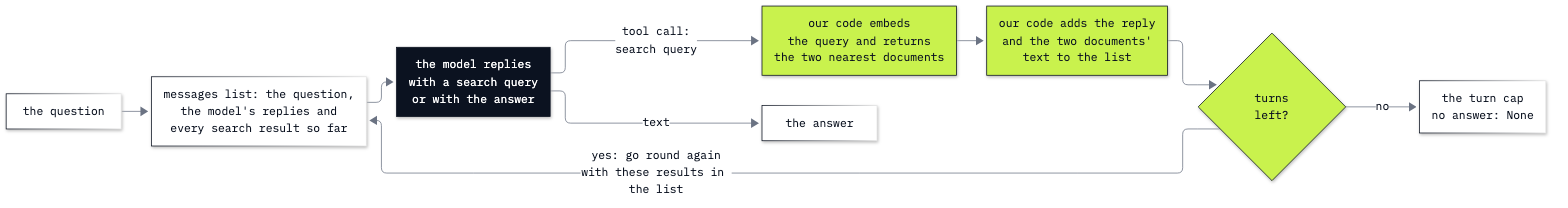

In [16]:
from IPython.display import Image

Image(str(ROOT / "13_Agentic_RAG" / "resources" / "lab13_agentic_rag.png"), width=760)

How to read the drawing:

- The dark box is the model's step: it replies with a search query (a tool call) or with text.
- The lime boxes are our code: it runs the search, adds the reply and the result to `messages`, and checks whether
  turns are left.
- There are two ways out: the answer, and the turn cap.

Follow our run round it. **Turn 1:** the model writes *dentist address*, our code returns `health.md` and `okafor.md`, and the
arrow goes back to the list. **Turn 2:** the model writes *Mia Rana clinic address*, built on the name it read, and our code returns
`rana.md`. **Turn 3:** the model replies with text, and the run leaves through the answer.

**Checkpoint C.** Two searches: the first *dentist address*, the second with "Mia Rana" in it, returning `rana.md`. The answer
gives 12 Garden Street, second floor. "Mia Rana" is not in the question and is in `health.md`.

---

## Part D: Stop the loop with a turn cap, and see how it ends on a question the notes cannot answer

A loop that can always search again needs two ways to stop: the model's answer, which includes "I do not know", and
our turn cap. We try each in turn.

### The turn cap

The same question with `max_turns=2`. Before you run it: the answer takes three turns. What will `answer` be?

In [17]:
answer, queries = run_loop(QUESTION, SYSTEM_AGAIN, max_turns=2)
print()
print("answer:", answer)

turn 1: search('dentist address')
    [health.md] My dentist is Mia Rana. My GP is Dr Okafor. Check-ups with both in March.
    [okafor.md] Dr Okafor's surgery: 3 Mill Lane. Open 8:00 to 18:00. Book online.


turn 2: search('Mia Rana clinic address')
    [rana.md] Mia Rana: 12 Garden Street, second floor. Ring the top bell. Closed on Fridays.
    [health.md] My dentist is Mia Rana. My GP is Dr Okafor. Check-ups with both in March.

answer: None


Turn 1 searched *dentist address* and turn 2 searched *Mia Rana clinic address*, which returned `rana.md` with the address. Then the turns ran out. The note with the answer was already in `messages`, and the cap ended the loop before a third call could send it to the model, so `answer` is `None`.

**Important:** `None` is not an empty answer. It means our code stopped the run, and whoever asked must be told that
there is no answer, never shown `None` as a reply.

### A question the notes cannot answer

None of my notes has a phone number. What does the loop do with *What is my dentist's phone number?*

In [18]:
answer, queries = run_loop("What is my dentist's phone number?", SYSTEM_AGAIN)
print()
print("answer:", answer)

turn 1: search('dentist phone number')
    [health.md] My dentist is Mia Rana. My GP is Dr Okafor. Check-ups with both in March.
    [okafor.md] Dr Okafor's surgery: 3 Mill Lane. Open 8:00 to 18:00. Book online.


turn 2: search('Mia Rana contact phone')
    [rana.md] Mia Rana: 12 Garden Street, second floor. Ring the top bell. Closed on Fridays.
    [health.md] My dentist is Mia Rana. My GP is Dr Okafor. Check-ups with both in March.



answer: I don’t know your dentist’s phone number. My notes identify Mia Rana as your dentist, but don’t list a phone number.


Two searches: *dentist phone number*, then *Mia Rana contact phone*, again built on the name from `health.md`. The second returned `rana.md`, which has an address and no phone number. The answer: *“I don’t know your dentist’s phone number. My notes identify Mia Rana as your dentist, but don’t list a phone number.”* The run ended by itself on turn 3, inside the cap of 5.

Notice what the search returned. `search` has no cut-off score: it always returns the two nearest notes, even when
neither has what the question asks for. So the model never gets an empty result here; it gets two notes that do not
answer, and it has to read them and say so. The system message's last rule, "If the notes do not say, say you do not
know", is the line that turns that into an honest answer.

**Checkpoint D.** With `max_turns=2`: two searches, the second returning `rana.md`, and `answer: None`. On the phone
question: two searches, the second with "Mia Rana" in it, and an answer that says the notes give no phone number.

---

## What you can do now

- Build a search over short texts: embed them in one request, score them against a query with `D @ q`, and keep the
  nearest (Part A).
- Say why one search with the question's words can miss the note that has the answer (Part A).
- Describe a search as a tool, run the model's query with our own code and send the result back, one turn at a time
  (Part B).
- Read the queries a model writes, and say which words came from the question and which from a note it read (Part C).
- Say what the sentence *Search again while the question is still open* changed (Parts B and C).
- Run the searches in a loop with a turn cap, and tell a run the cap stopped (`None`) from an answer, including an
  honest "I do not know" (Part D).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `BadRequestError: Error code: 400 - Function tools with reasoning_effort are not supported for <model> in /v1/chat/completions.` | on Chat Completions this model calls tools only when the reasoning effort is `none` | set `REASONING_EFFORT=none` in `models.env` and run the first cell again |
| `BadRequestError: Error code: 400 - An assistant message with 'tool_calls' must be followed by tool messages responding to each 'tool_call_id'.` | `messages` has the model's tool call with no `tool` message after it, for example when the search cell stopped with an error after `messages.append(reply)` | run Part B again from *Turn 1*, which starts a fresh `messages` list |

## Challenge

1. **A question the first search answers.** Run `run_loop("Where is my GP's surgery?", SYSTEM_AGAIN)`. How many
   searches does the model make? Expected: the first search already returns `okafor.md`, and the answer is 3 Mill
   Lane. In most runs that one search is all; in a few the model searches once more, with Dr Okafor's name, before it
   answers (the solution's run did). Either way, compare with the dentist question: here no second search was needed
   to find the answer.
2. **A question where the added sentence is not enough.** Run `run_loop("Which day is my dentist closed?",
   SYSTEM_AGAIN)` and read the second query. Expected: in most runs the second query does not use the name (for
   example *dentist opening hours closed*), `rana.md` never comes back, and the answer says the notes do not say. Write
   one more sentence for the system message so that the model searches for a name it reads in a note, and run the
   question again. Expected: a second query with "Mia Rana" in it, and the answer Fridays. Then run the address
   question with your new system message to check that it still works.

The worked solution, run with its outputs, is in `solved/13a_meet_agentic_rag_solution.ipynb`.

## Resources

- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool schemas, strict
  mode, tool calls and sending results back
- [OpenAI: vector embeddings](https://developers.openai.com/api/docs/guides/embeddings): what an embedding is, and
  several texts embedded in one request
- [NumPy: `argsort`](https://numpy.org/doc/stable/reference/generated/numpy.argsort.html): the positions that sort
  an array

Next: [notebook 2, the search tool at the Chinook support desk](13b_agentic_rag_at_the_desk.ipynb).